# Newton and Cubic Interpolation for Scalar Optimization

Minimize the strictly convex scalar objective $f(x)=e^{x-3}-x/2-2$ using derivative-based Newton steps and a bracketed cubic interpolant. The analytical solution is $x^*=3-\log 2\approx2.30685281944$, with $f^*=-(3-\log 2)/2-1.5\approx-2.65342640972$.

[Technical notes](../docs/newton_and_cubic_interpolation.md) · [Saved figures](../results/newton_and_cubic_interpolation/)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Objective and derivatives

$f'(x)=e^{x-3}-1/2$ and $f''(x)=e^{x-3}>0$, so the stationary point is the unique global minimizer.

In [2]:
def f(x):
    """Objective function: f(x) = exp(x-3) - x/2 - 2."""
    return np.exp(x - 3.0) - 0.5 * x - 2.0

def grad_f(x):
    """First derivative f'(x)."""
    return np.exp(x - 3.0) - 0.5

def hess_f(x):
    """Second derivative f''(x)."""
    return np.exp(x - 3.0)

# true minimizer (from solving f'(x)=0)
x_star = 3.0 - np.log(2.0)

## Armijo line search

Shrink the trial length by a factor of 0.5 until the sufficient-decrease inequality holds, using $\sigma=0.1$.

In [3]:
def backtracking(x, p, g, alpha0=1.0, beta=0.5, sigma=0.1):
    """
    Armijo backtracking line search in 1D.
    """
    alpha = alpha0
    fx = f(x)
    while f(x + alpha * p) > fx + sigma * alpha * g * p:
        alpha *= beta
    return alpha


## Newton iteration

The scalar Newton direction is $p=-f'(x)/f''(x)$. Terminate when $|f'(x)|<10^{-8}$ and track distance to the analytical optimum.

In [4]:
def newton_backtracking(x0, alpha0=1.0, beta=0.5, sigma=0.1,
                        tol=1e-8, max_iter=100):
    """
    Newton's method for 1D with backtracking line search.

    Returns:
        xs     : list of iterates x_k
        fvals  : list of f(x_k)
        dists  : list of |x_k - x*|
        alphas : list of step sizes alpha_k
        k      : iteration at which convergence occurred
    """
    x = float(x0)
    xs, fvals, dists, alphas = [], [], [], []

    for k in range(max_iter):
        g = grad_f(x)
        H = hess_f(x)

        xs.append(x)
        fvals.append(f(x))
        dists.append(abs(x - x_star))

        if abs(g) < tol:
            return xs, fvals, dists, alphas, k

        p = -g / H  # Newton direction (1D)
        alpha = backtracking(x, p, g, alpha0=alpha0, beta=beta, sigma=sigma)
        alphas.append(alpha)

        x = x + alpha * p

    return xs, fvals, dists, alphas, max_iter

## Newton experiment and convergence plots

Start from $x_0=0$ and use initial trial step 1.

=== Newton with alpha0 = 1.0 ===
Convergence iteration: 4
Final x: 2.3068528194402256
true minimizer (from solving f'(x)=0): 2.3068528194400546
Final f(x): -2.6534264097200273


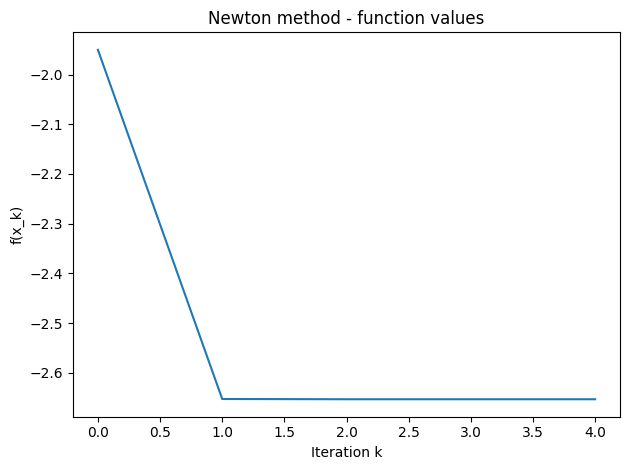

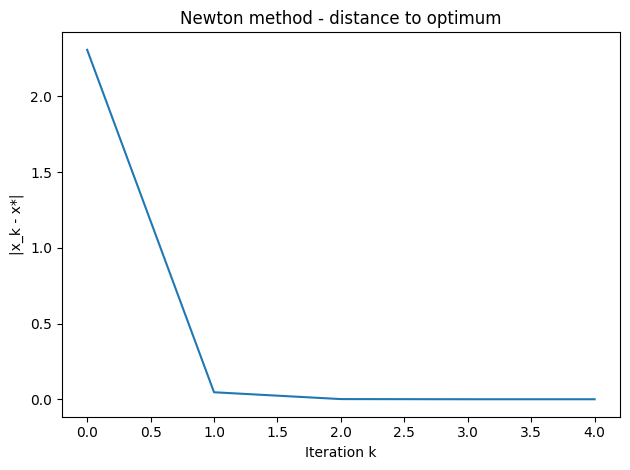

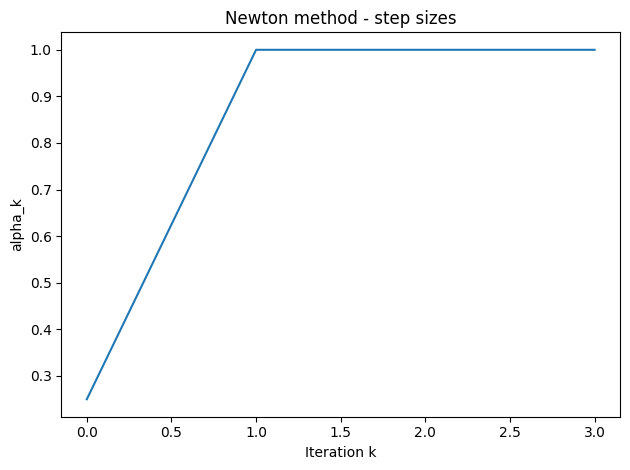

In [9]:
x0 = 0.0          # starting point
alpha0 = 1.0      # initial step size for plots

xs, fvals, dists, alphas, k_conv = newton_backtracking(
    x0, alpha0=alpha0, tol=1e-8, max_iter=100)

print("=== Newton with alpha0 = 1.0 ===")
print("Convergence iteration:", k_conv)
print("Final x:", xs[-1])
print("true minimizer (from solving f'(x)=0):",x_star)
print("Final f(x):", fvals[-1])

    # ----- Plot f(x_k) -----
plt.figure()
plt.plot(range(len(fvals)), fvals)
plt.xlabel("Iteration k")
plt.ylabel("f(x_k)")
plt.title("Newton method - function values")
plt.tight_layout()
plt.savefig("newton_fvals.png", dpi=300)

    # ----- Plot |x_k - x*| -----
plt.figure()
plt.plot(range(len(dists)), dists)
plt.xlabel("Iteration k")
plt.ylabel("|x_k - x*|")
plt.title("Newton method - distance to optimum")
plt.tight_layout()
plt.savefig("newton_dist.png", dpi=300)

    # ----- Plot alpha_k -----
plt.figure()
plt.plot(range(len(alphas)), alphas)
plt.xlabel("Iteration k")
plt.ylabel("alpha_k")
plt.title("Newton method - step sizes")
plt.tight_layout()
plt.savefig("newton_alpha.png", dpi=300)

## Effect of initial trial step

Repeat the Newton experiment for five values with the same stopping tolerance.

In [7]:
alpha0_list = [0.1, 0.5, 1.0, 2.0, 5.0]
print("\n=== Effect of alpha0 on convergence ===")
for a0 in alpha0_list:
    xs_exp, fvals_exp, dists_exp, alphas_exp, it = newton_backtracking(
        x0, alpha0=a0, tol=1e-8, max_iter=1000
    )
    print(f"alpha0 = {a0:3.1f} -> iterations = {it}, "
          f"x_final = {xs_exp[-1]:.10f}, f(x_final) = {fvals_exp[-1]:.12f}")


=== Effect of alpha0 on convergence ===
alpha0 = 0.1 -> iterations = 166, x_final = 2.3068527999, f(x_final) = -2.653426409720
alpha0 = 0.5 -> iterations = 23, x_final = 2.3068528089, f(x_final) = -2.653426409720
alpha0 = 1.0 -> iterations = 4, x_final = 2.3068528194, f(x_final) = -2.653426409720
alpha0 = 2.0 -> iterations = 4, x_final = 2.3068528194, f(x_final) = -2.653426409720
alpha0 = 5.0 -> iterations = 12, x_final = 2.3068528314, f(x_final) = -2.653426409720


## Cubic interpolation search

Use endpoint function values and derivatives to construct a cubic model on a bracket containing the stationary point.

In [15]:
import numpy as np
import math

### Objective and first derivative

The interpolant uses the same objective as the Newton experiment.

In [11]:
def f(x):
    return math.exp(x - 3.0) - 0.5 * x - 2.0

def df(x):
    return math.exp(x - 3.0) - 0.5


### Cubic Hermite model

Construct $p(t)=c_0+c_1t+c_2t^2+c_3t^3$ from $p(a)=f(a),p(b)=f(b),p'(a)=f'(a),p'(b)=f'(b)$. Solve the quadratic equation $p'(t)=0$ and choose an interior candidate by its actual objective value.

In [12]:
def cubic_minimizer(a, b):
    """
    Build a cubic p(t) that interpolates f, f' at a and b:
        p(a)=f(a), p'(a)=f'(a), p(b)=f(b), p'(b)=f'(b)
    and return the minimizer of p(t) in (a,b).
    """
    fa, fb = f(a), f(b)
    ga, gb = df(a), df(b)

    A = np.array([
        [1, a, a*a, a*a*a],
        [0, 1, 2*a, 3*a*a],
        [1, b, b*b, b*b*b],
        [0, 1, 2*b, 3*b*b]
    ], dtype=float)
    y = np.array([fa, ga, fb, gb], dtype=float)

    c0, c1, c2, c3 = np.linalg.solve(A, y)

    # p'(t) = c1 + 2 c2 t + 3 c3 t^2
    qa, qb, qc = 3*c3, 2*c2, c1
    disc = qb*qb - 4*qa*qc
    if disc < 0:
        return None

    r1 = (-qb + math.sqrt(disc)) / (2*qa)
    r2 = (-qb - math.sqrt(disc)) / (2*qa)

    candidates = [r for r in (r1, r2) if a < r < b]
    if not candidates:
        return None

    # choose candidate with smaller f value
    candidates.sort(key=f)
    return candidates[0]

### Bracket refinement

Update the endpoint according to the sign of $f'(x)$, preserving $f'(a)<0<f'(b)$.

In [13]:
def cubic_search(a0=0.0, b0=4.0, tol=1e-8, max_iter=50):
    """
    1D cubic interpolation search on [a0,b0].
    Assumes df(a0) < 0 < df(b0).
    """
    a, b = a0, b0
    xs = []

    for k in range(max_iter):
        x = cubic_minimizer(a, b)
        xs.append(x)

        if abs(df(x)) < tol:
            return x, k+1, xs

        # keep the bracketing condition df(a)<0<df(b)
        if df(x) > 0:
            b = x
        else:
            a = x

    return x, max_iter, xs


### Numerical cubic interpolation experiment

Begin with the interval $[0,4]$ and stop at the derivative tolerance.

In [16]:
x_star, iters, seq = cubic_search(0.0, 4.0, tol=1e-8, max_iter=50)
print("Cubic interpolation search:")
print("Iterations =", iters)
print("x*        =", x_star)
print("f(x*)     =", f(x_star))
print("sequence  =", seq)

Cubic interpolation search:
Iterations = 4
x*        = 2.306852819606583
f(x*)     = -2.6534264097200273
sequence  = [np.float64(2.2596354121541022), np.float64(2.344418110444988), np.float64(2.3068514246107914), np.float64(2.306852819606583)]


## Results and interpretation

| Initial trial step | Newton convergence index |
|---:|---:|
| 0.1 | 166 |
| 0.5 | 23 |
| 1 | 4 |
| 2 | 4 |
| 5 | 12 |

With initial step 1, Newton obtains $x=2.3068528194402256$ and $f=-2.6534264097200273$. The cubic search returns $x=2.306852819606583$ and the same displayed objective in four interpolant evaluations. Newton with trial steps 1 and 2 is the fastest of the tested Newton configurations; small steps slow progress near the solution, while large steps can trigger backtracking.

The two algorithms use different information and initialization: Newton uses local second derivatives, whereas cubic search uses values and first derivatives at both endpoints. Equal iteration counts do not imply equal evaluation cost. The cubic routine assumes an interior stationary candidate exists; it does not implement a general fallback when interpolation fails.